Epoch 1/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3952 - loss: 1.7527 - val_accuracy: 0.6900 - val_loss: 1.0117
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6985 - loss: 0.9133 - val_accuracy: 0.7733 - val_loss: 0.7046
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7926 - loss: 0.6496 - val_accuracy: 0.8167 - val_loss: 0.5839
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8559 - loss: 0.4686 - val_accuracy: 0.8300 - val_loss: 0.5317
Epoch 5/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8863 - loss: 0.3662 - val_accuracy: 0.8567 - val_loss: 0.4556
Epoch 6/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8996 - loss: 0.3054 - val_accuracy: 0.8467 - val_loss: 0.4774
Epoch 7/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9270 - loss: 0.2294 - val_accuracy: 0.8700 - val_loss: 0.4187
Epoch 8/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9319 - loss: 0.2016 - val_accuracy: 0.8600 - val_loss:

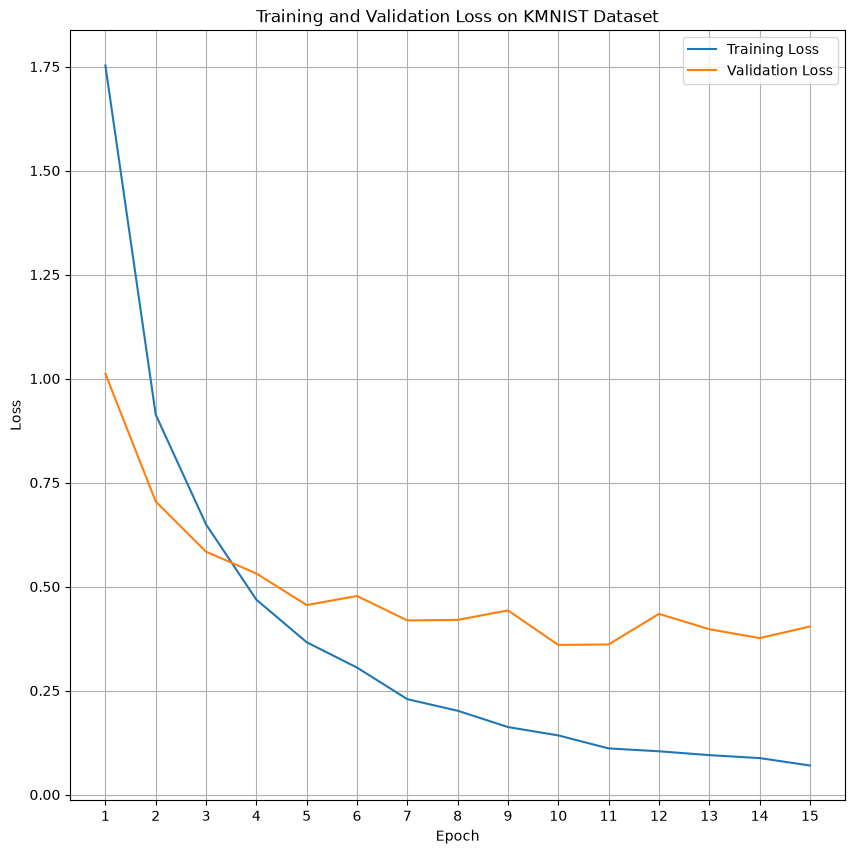

Q6.2 MC Dropout Test accuracy: 78.80%
Q6.3 Average epistemic uncertainty: 0.006


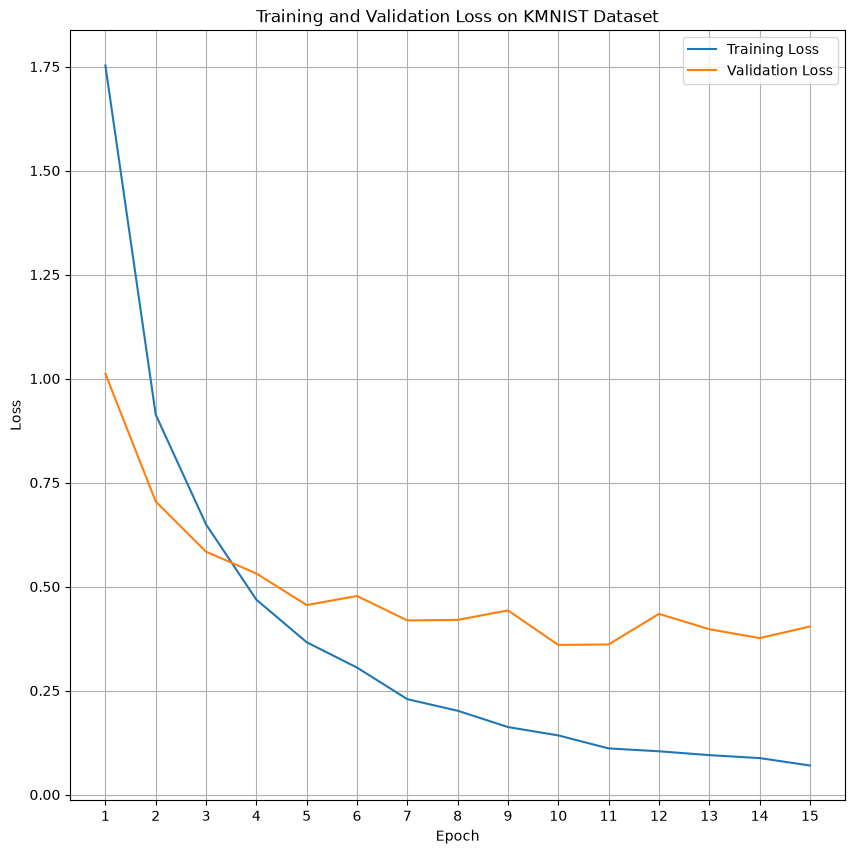

In [7]:
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

# set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# load training and test data from the KMNIST dataset
train_ds, test_ds = tfds.load(
    "kmnist",
    split=["train[:3000]", "test[:500]"],
    as_supervised=True,
    shuffle_files=False
)

# use 10% of the training data for validation
validation_ds = train_ds.skip(2700)
train_ds = train_ds.take(2700)

# normalize pixel values from [0, 255] to [0, 1]
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = train_ds.map(normalize)
validation_ds = validation_ds.map(normalize)
test_ds = test_ds.map(normalize)

# batch datasets
train_ds = train_ds.batch(32)
validation_ds = validation_ds.batch(32)
test_ds = test_ds.batch(32)

# build CNN model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # first convolutional block with 32 filters
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # second convolutional block with 64 filters
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # flatten features maps into 1D
    tf.keras.layers.Flatten(),

    # fully connected layer with dropout for regularization
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.25),

    # output layer with one neuron for each category
    tf.keras.layers.Dense(10, activation="softmax")
])

# configure SGD optimizer
optimizer = tf.keras.optimizers.SGD(
    learning_rate=0.01,
    momentum=0.9,
)

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=15
)

test_loss, test_acc = model.evaluate(test_ds)
print(f"Q6.1 Test accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(10, 10))

epochs = range(1, len(history.history["loss"]) + 1)

plt.plot(epochs, history.history["loss"], label="Training Loss")
plt.plot(epochs, history.history["val_loss"], label="Validation Loss")

plt.xticks(epochs)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss on KMNIST Dataset")
plt.legend()
plt.grid(True)
plt.show()

# perform 20 stochastic forward passes with dropout enabled during inference
mc_predictions = []

for _ in range(20):
    predictions = []

    for images, labels in test_ds:
        # keep dropout active to produce different predictions
        batch_predictions = model(images, training=True)

        predictions.append(batch_predictions.numpy())

    mc_predictions.append(np.concatenate(predictions, axis=0))

# stack predictions into array of shape (20, 500, 10)
mc_predictions = np.stack(mc_predictions, axis=0)

# average predicted probabilities
mean_predictions = np.mean(mc_predictions, axis=0)

# select the class with the highest average probability
pred_classes = np.argmax(mean_predictions, axis=1)

# retrieve test labels
test_labels  = np.concatenate(
    [label.numpy() for images, label in test_ds]
)

# calculate MC Dropout accuracy
mc_acc = np.mean(pred_classes == test_labels)
print(f"Q6.2 MC Dropout Test accuracy: {mc_acc * 100:.2f}%")

# calculate variance of each class probability
predictive_variance = np.var(mc_predictions, axis=0)

# average variance across the classes for each test image
sample_uncertainty = np.mean(predictive_variance, axis=1)

# calculate average epistemic uncertainty across all 500 test images
mean_uncertainty = np.mean(sample_uncertainty)
print(f"Q6.3 Average epistemic uncertainty: {mean_uncertainty:.3f}")

